# ***CT5146: Introduction to NLP (Online)***

# ***Assignment 1: Hate Speech Classification*** (Total 100 marks)
This assignment is focused on Hate Speech Classification from social media comments.

>  <font color="red">**Disclaimer:** This assignment may contain hate speech and offensive content, strictly for academic purposes. </font>

---

###  **Task Roadmap**

Here's what you'll be building, step by step:

| # | Section | Focus |
|---|---|---|
| 1️ | **Dataset & EDA** | Pick a dataset, justify it, explore the classes (One example provided ) |
| 2️ | **Training & Evaluation** | Train a classifier, evaluate it properly |
| 3️ | **Improve It** | Tune the *same* model, prove it got better |

Each section builds on the last - so a solid dataset and clean features in Sections 1 will make Sections 2-3 much smoother.

---

---
# **Dataset Details**

The dataset can be divided into **three parts**: **Training**, **Development (Dev)**, and **Test** sets.  

1. **Training set**  
   - Used to **train your model** (learn patterns from the data).  
   - This is the largest portion of the dataset.  

2. **Development (Dev) set**  
   - A small part of the training data that is **held out**.  
   - Used to **validate your model** while training and for **hyperparameter tuning**.  
   - Helps avoid overfitting (your model performing well on training but poorly on unseen data).  

3. **Test set**  
   - Contains **unlabeled data** (labels are hidden).
   - Used only for **final evaluation** of your model.  
   - You will generate a **prediction file** for this set and submit it.  

---

# Installing and Importing Packages

> **Note:** This setup cell is not directly graded. You may install and import any Python packages required for your experiments.  
> Commonly used libraries for this assignment may include `pandas`, `numpy`, `matplotlib`, `scikit-learn`, and relevant NLP libraries.

In [ ]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk

---

# **Section 1: Dataset Selection & Exploratory Data Analysis**

### `Total = 30 marks`

Before building your classification model, select a suitable **hate-speech classification dataset** and explore its main characteristics.

> **Note:** You may use one of the example datasets provided in Task 1a, or select another appropriate publicly available dataset.

| Task | What you'll do | Marks |
|---|---|---|
| **1a** | Select and load a dataset, and prepare Train / Dev / Test splits | `5` |
| **1b** | Plot the **class distribution** using a suitable visualisation | `10` |
| **1c** | Carry out **Exploratory Data Analysis (EDA)** relevant to your dataset, such as text length, vocabulary size, common n-grams, or other informative characteristics | `5` |
| **1d** | Explain your **dataset selection** and the main findings from your EDA | `10` |

> A clear understanding of the dataset will help you make better decisions in the later modelling and evaluation sections.

---

## **1a: Dataset** (5 marks)

Select and load **one suitable hate-speech classification dataset** for this assignment.

> **Note:** You may choose **one of the example datasets listed below**, or you may use **another appropriate publicly available dataset** of your choice.

Example datasets:

1. https://huggingface.co/datasets/christinacdl/binary_hate_speech  
2. https://huggingface.co/datasets/tdavidson/hate_speech_offensive  
3. https://huggingface.co/datasets/tweets-hate-speech-detection/tweets_hate_speech_detection  
4. https://huggingface.co/datasets/badmatr11x/hate-offensive-speech  

If you choose a different dataset, it should contain:

- textual input data;
- clearly defined class labels;
- enough examples for model training and evaluation.

Use the dataset's existing **Train / Dev / Test splits** where available. If suitable splits are not provided, create them yourself.

Tutorial: [Loading a dataset from Hugging Face](https://huggingface.co/docs/datasets/load_hub)

In [ ]:
# YOUR CODE HERE
# Load the dataset info to check the dataset before loading
from datasets import load_dataset_builder

ds = load_dataset_builder("christinacdl/binary_hate_speech")

ds.info.features

{'text': Value('string'), 'label': Value('string')}

In [ ]:
# Check how many splits the dataset has
from datasets import get_dataset_split_names

get_dataset_split_names("christinacdl/binary_hate_speech")

['train', 'validation', 'test']

In [ ]:
# Load dataset
from datasets import load_dataset

dataset = load_dataset("christinacdl/binary_hate_speech")

In [ ]:
print(dataset.shape) # print the shape of dataset

{'train': (31060, 2), 'validation': (3883, 2), 'test': (3883, 2)}


In [ ]:
# We will just use the train dataset
train_dataset = dataset['train']
train_dataset[:10]

{'text': ["She won't be there for long.",
  'i guess eu is gonna have to back track a little. what we ..usa says matters , more disappointment for msm ',
  '@user @user @user @user @user I can understand that and if it’s someone I know I’ll debate with them but I’m not willing to spend that much time trying to change the mind of someone I don’t know I tryed that with people and gun control and it just get stupid because they won’t try to understand ',
  "Media Matters hates Joe diGenova - that's a resounding endorsement, IMHO. ",
  "@user @user @user @user thanks to the best b'day wknd kickoff   friday bitches",
  '@USER Dont be that guy.  Whoops.  Too late.  You are that guy.  Unfollowed...',
  " @user the @user programme is here! the excitement stas on 14th july...can't wait! #filmfestival #indianindiecinema #london #exâ\x80¦",
  '@USER @USER Funny how so many liberals throw around the word bigot when someone has a different opinion. URL',
  'ramadhan kareem, happy for all... :d  #sm

## **1b: Class Distribution** (10 marks)

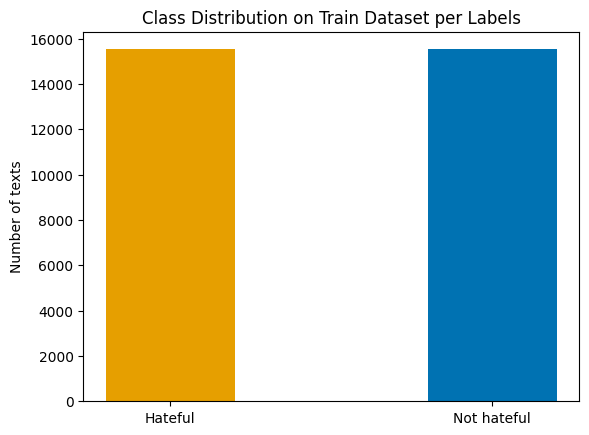

In [ ]:
# YOUR CODE HERE
# Let's plot how many hateful and non-hateful rows there are in the dataset
# Will use only the train set and split it later
# Import Counter
from collections import Counter

train_counts = Counter(dataset["train"]["label"])

labels = ["Hateful", "Not hateful"]

counts = [
    train_counts["OFF_HATEFUL_TOXIC"],
    train_counts["NOT_OFF_HATEFUL_TOXIC"]
]


plt.bar(labels, counts, width=0.4, color=["#E69F00", "#0072B2"])
plt.ylabel("Number of texts")
plt.title("Class Distribution on Train Dataset per Labels")
plt.show()


## **1c: Exploratory Data Analysis (EDA)** (5 marks)

In [ ]:
# YOUR CODE HERE
# Convert the dataset into pandas
df = dataset['train'].to_pandas()

### Missing and Duplicated Row Check
Check if the dataframe has any missing or duplicated values. There are no missing or duplicated values.

In [ ]:
# Print the count of missing values from all dfs
print(df.isnull().sum())

text     0
label    0
dtype: int64


In [ ]:
# Print the count of duplicated values from all dfs.
print(df.duplicated().sum())


0


In [ ]:
df.describe()

,text,label
count,31060,31060
unique,30842,2
top,"One more of tonight's dog walk sunset. AKA, in...",NOT_OFF_HATEFUL_TOXIC
freq,2,15530


### Clean the training data

In [ ]:
# Let's first clean the train dataset by removing special characters such as mention, hashtag etc
# Also when doing the text preprocessing, I realised there were a lot of unicode encoding problems from the original dataset
import re # Import regex

pd.set_option('display.max_colwidth', None) # Remove text truncation for better preview the text

def fix_encoding(text):
    """
    Funxtion to fix the encoding error from the dataset
    """
    try:
        return text.encode('latin1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text

def clean_text(text):
    """
    Function to fix incorrect encoding, remove mentions, url etc
    """
    text = fix_encoding(text) # apply fix_encoding on text
    text = re.sub(r'@\w+', '', text) # Remove mentions
    text = re.sub(r'(https?://\S+|www\.\S+)', '', text) # Remove URLs
    text = re.sub(r'#', '', text) # Remove # but keep hashtag word
    text = text.replace('’', "'") # Replace to have one type of '

    # To lowercase
    text = text.lower()

    return text # Return the text

df['text'] = df['text'].apply(clean_text) # Apply the clean_test on text column

In [ ]:
df.head(20)

,text,label
0,she won't be there for long.,NOT_OFF_HATEFUL_TOXIC
1,"i guess eu is gonna have to back track a little. what we ..usa says matters , more disappointment for msm",NOT_OFF_HATEFUL_TOXIC
2,i can understand that and if it's someone i know i'll debate with them but i'm not willing to spend that much time trying to change the mind of someone i don't know i tryed that with people and gun control and it just get stupid because they won't try to understand,OFF_HATEFUL_TOXIC
3,"media matters hates joe digenova - that's a resounding endorsement, imho.",NOT_OFF_HATEFUL_TOXIC
4,thanks to the best b'day wknd kickoff friday bitches,NOT_OFF_HATEFUL_TOXIC
5,dont be that guy. whoops. too late. you are that guy. unfollowed...,NOT_OFF_HATEFUL_TOXIC
6,the programme is here! the excitement stas on 14th july...can't wait! filmfestival indianindiecinema london ex…,NOT_OFF_HATEFUL_TOXIC
7,funny how so many liberals throw around the word bigot when someone has a different opinion. url,NOT_OFF_HATEFUL_TOXIC
8,"ramadhan kareem, happy for all... :d smile ramadhan child sharinghappiness cantik…",NOT_OFF_HATEFUL_TOXIC
9,one imagines you are being sarcastic. one worries that you are not.,NOT_OFF_HATEFUL_TOXIC


In [ ]:
# Check the tail to see how clean the text is
df.tail(10)

,text,label
31050,"the real and antisemites are and the progressive minions, not freedom loving americans",OFF_HATEFUL_TOXIC
31051,amazing how the pope is afraid of the truth,OFF_HATEFUL_TOXIC
31052,not a gd day tdy. no wonder it rain most of the day. emo,NOT_OFF_HATEFUL_TOXIC
31053,💋💓💓 . michealkorswhitebagcuteinstahapgyinstacoolinstagram 0608,NOT_OFF_HATEFUL_TOXIC
31054,so i found this uncle by the road side at the market this morning and almost everything he sells could be a potential diy project.,NOT_OFF_HATEFUL_TOXIC
31055,actual animals however do object 😏,NOT_OFF_HATEFUL_TOXIC
31056,&8220;: my tweets trash&8221;,OFF_HATEFUL_TOXIC
31057,confusing circumstances seem to get in the way of your high ho... more for virgo,NOT_OFF_HATEFUL_TOXIC
31058,now new reading material for my entrepreneurial updates 🤓 blessed onamission…,NOT_OFF_HATEFUL_TOXIC
31059,stop w 'we have to worry about the children' no we do not-many r >20yrs old go home and make your country better or enter ours legally nodaca we can't afford them,OFF_HATEFUL_TOXIC


### Transform Text Label to Numeric
Change the label that is currently set to string to a numeric 0 and 1.

In [ ]:
from IPython.utils.text import string
# Create a dict to map the labels to numeric
label_numeric_map = {
    'OFF_HATEFUL_TOXIC': 1,
    'NOT_OFF_HATEFUL_TOXIC': 0
}

# Create a function to check if the label is in numeric otherwise apply the above
def label_to_num(df):

    # If the label of df is not numeric, apply label_numeric_map
    if not pd.api.types.is_numeric_dtype(df['label']):
        df['label'] = df['label'].map(label_numeric_map)
    else: # otherwise just print the statement
        print(f"Label of {df} is already numeric")

label_to_num(df)

print(pd.api.types.is_numeric_dtype(df['label']))

True


### Text Length

In [ ]:
# Create a new column counting all the words in the text column
df['count_words'] = df['text'].str.split().str.len()
df.head()

,text,label,count_words
0,she won't be there for long.,0,6
1,"i guess eu is gonna have to back track a little. what we ..usa says matters , more disappointment for msm",0,21
2,i can understand that and if it's someone i know i'll debate with them but i'm not willing to spend that much time trying to change the mind of someone i don't know i tryed that with people and gun control and it just get stupid because they won't try to understand,1,52
3,"media matters hates joe digenova - that's a resounding endorsement, imho.",0,11
4,thanks to the best b'day wknd kickoff friday bitches,0,9


In [ ]:
# See the range of the text length
max_count_words = df.loc[df['count_words'].idxmax()]['count_words']
min_count_words = df.loc[df['count_words'].idxmin()]['count_words']

print(f"df's text range from {min_count_words} to {max_count_words}")

df's text range from 0 to 311


### Vocabulary Size

In [ ]:
# Check the unique vocabulary size in the df
# Since we have two labels, better to separate the vocabulary size set
# according to the labels

# Get the full texts for non hateful and hateful
non_hateful_text_full = " ".join(df.loc[df['label'] == 0, "text"])
hateful_text_full = " ".join(df.loc[df['label'] == 1, "text"])

# Create a set of unique words from each full text strings
non_hateful_voca = set(non_hateful_text_full.split())
hateful_voca = set(hateful_text_full.split())

# Check the length of the vocabulary
total_non_hateful_voca = len(non_hateful_voca)
total_hateful_voca = len(hateful_voca)

print(total_non_hateful_voca)
print(total_hateful_voca)

44166
36778


In [ ]:
print(list(non_hateful_voca)[:10])

['चिढ़', 'monthe', '100-300k', 'some', 'connected.', 'suffolk', "nh's", 'crackers', "'", 'scarfing']


In [ ]:
# Count the frequencies of the vocabulary

non_hateful_counts = Counter(non_hateful_text_full.split())
hateful_counts = Counter(hateful_text_full.split())

# Most frequent words
print(non_hateful_counts.most_common(10))
print(hateful_counts.most_common(10))

[('the', 9182), ('to', 6715), ('a', 5034), ('and', 4728), ('is', 4150), ('of', 4068), ('you', 3645), ('i', 3425), ('in', 3188), ('for', 2741)]
[('the', 10048), ('to', 7495), ('a', 7052), ('is', 5750), ('and', 5696), ('you', 5272), ('of', 4552), ('in', 3521), ('i', 3368), ('are', 3247)]


Seeing from the above, the common words are all stopwords. These need to be removed.

### N-grams

Create 2-grams of words

In [ ]:
# Create a column that splits texts into words
df['text_split_to_words'] = df['text'].str.split()

def generate_ngram(df, n):
    """
    Function for creating n-grams for texts and adding a column to the df
    """
    df[f"{n}-gram"] = df['text_split_to_words'].apply(
        lambda word: [tuple(word[i:i+n]) for i in range(len(word)-n+1)]
    )
generate_ngram(df, 2)
df.head()

,text,label,count_words,text_split_to_words,2-gram
0,she won't be there for long.,0,6,"[she, won't, be, there, for, long.]","[(she, won't), (won't, be), (be, there), (there, for), (for, long.)]"
1,"i guess eu is gonna have to back track a little. what we ..usa says matters , more disappointment for msm",0,21,"[i, guess, eu, is, gonna, have, to, back, track, a, little., what, we, ..usa, says, matters, ,, more, disappointment, for, msm]","[(i, guess), (guess, eu), (eu, is), (is, gonna), (gonna, have), (have, to), (to, back), (back, track), (track, a), (a, little.), (little., what), (what, we), (we, ..usa), (..usa, says), (says, matters), (matters, ,), (,, more), (more, disappointment), (disappointment, for), (for, msm)]"
2,i can understand that and if it's someone i know i'll debate with them but i'm not willing to spend that much time trying to change the mind of someone i don't know i tryed that with people and gun control and it just get stupid because they won't try to understand,1,52,"[i, can, understand, that, and, if, it's, someone, i, know, i'll, debate, with, them, but, i'm, not, willing, to, spend, that, much, time, trying, to, change, the, mind, of, someone, i, don't, know, i, tryed, that, with, people, and, gun, control, and, it, just, get, stupid, because, they, won't, try, to, understand]","[(i, can), (can, understand), (understand, that), (that, and), (and, if), (if, it's), (it's, someone), (someone, i), (i, know), (know, i'll), (i'll, debate), (debate, with), (with, them), (them, but), (but, i'm), (i'm, not), (not, willing), (willing, to), (to, spend), (spend, that), (that, much), (much, time), (time, trying), (trying, to), (to, change), (change, the), (the, mind), (mind, of), (of, someone), (someone, i), (i, don't), (don't, know), (know, i), (i, tryed), (tryed, that), (that, with), (with, people), (people, and), (and, gun), (gun, control), (control, and), (and, it), (it, just), (just, get), (get, stupid), (stupid, because), (because, they), (they, won't), (won't, try), (try, to), (to, understand)]"
3,"media matters hates joe digenova - that's a resounding endorsement, imho.",0,11,"[media, matters, hates, joe, digenova, -, that's, a, resounding, endorsement,, imho.]","[(media, matters), (matters, hates), (hates, joe), (joe, digenova), (digenova, -), (-, that's), (that's, a), (a, resounding), (resounding, endorsement,), (endorsement,, imho.)]"
4,thanks to the best b'day wknd kickoff friday bitches,0,9,"[thanks, to, the, best, b'day, wknd, kickoff, friday, bitches]","[(thanks, to), (to, the), (the, best), (best, b'day), (b'day, wknd), (wknd, kickoff), (kickoff, friday), (friday, bitches)]"


In [ ]:
# Create a counter for 2-grams
n2_gram_counter = Counter(
    ngram
    for row in df['2-gram']
    for ngram in row
    )
n2_gram_counter.most_common(10) # Get the top 10 common 2-grams

[(('in', 'the'), 1384),
 (('you', 'are'), 1380),
 (('of', 'the'), 1353),
 (('is', 'a'), 1317),
 (('he', 'is'), 1254),
 (('she', 'is'), 1057),
 (('to', 'be'), 958),
 (('this', 'is'), 735),
 (('to', 'the'), 712),
 (('gun', 'control'), 700)]

The common 2-grams also include various stopwords.

### Train, Dev and Test split

In [ ]:
from sklearn.model_selection import train_test_split

# Split train first (80%) and leave the 20% as temp to make a second split
X_train, X_temp, y_train, y_temp = train_test_split(df['text'], df['label'],
                                                    test_size=0.20,
                                                    random_state=42,
                                                    stratify=df['label'])

# Split the temp set to halves for each dev and test
X_dev, X_test, y_dev, y_test = train_test_split(X_temp, y_temp,
                                                test_size=0.5,
                                                random_state=42,
                                                stratify=y_temp)

# Set the Xs into Pandas DataFrame
X_train = X_train.to_frame(name='text')
X_dev = X_dev.to_frame(name='text')
X_test = X_test.to_frame(name='text')

In [ ]:
print(X_train.shape)
print(y_train.shape)

print(X_dev.shape)
print(y_dev.shape)

print(X_test.shape)
print(y_test.shape)


(24848, 1)
(24848,)
(3106, 1)
(3106,)
(3106, 1)
(3106,)


## **1d: Explanation** (10 marks)

**Question:** Explain your dataset selection and your Exploratory Data Analysis (EDA) process.

Your answer should cover:
- **Why you selected this dataset?**
- **The EDA process carried out in Tasks 1a to 1c**. what you looked at (class distribution, text statistics, etc.).

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
# YOUR ANSWER HERE
Dataset has enough texts (31060).
The number of hateful and non-hateful texts are balanced (Each 15530).
Contains various hashtag, mention, emojis, special characters etc such are common on social media.
Corrupted texts (e.g. ð, â¦).
Majority of words from both single and 2-grams were all stopwords that needed to be extracted.

```

---

#  **Section 2**: Feature Extraction, Model Training & Evaluation

### `Total = 40 marks`

Time to build your baseline model. In this section, you will convert the text into suitable numerical features or embeddings, train a classical machine-learning classifier, and evaluate its performance using appropriate metrics.

| Task   | What you'll do                                                                                                                                                            | Marks |
| ------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ----: |
| **2a** | Perform **feature extraction** using a suitable technique |  `10` |
| **2b** | Train a suitable **classical ML baseline classifier** using the extracted features                                                                                        |  `10` |
| **2c** | **Predict and evaluate** the model using multiple appropriate evaluation metrics                                                                                          |  `10` |
| **2d** | Explain your **feature extraction method, model choice, evaluation metrics, and results**                                                                                 |  `10` |

>  Choose a feature representation and classical machine-learning model that are suitable for your dataset. Your goal here is to establish a clear and well-evaluated **baseline model**. You will improve this same model in Section 3.

---


## **2a: Feature Extraction / Text Representation** (10 marks)
Use a suitable feature extraction or text representation technique to convert the text data into numerical features that can be used by a classical machine-learning model.

* You may use an appropriate method such as: Bag-of-Words, TF-IDF, Word2Vec, FastText or another suitable feature representation method

Your implementation should clearly show how the training, validation, and test data are transformed.

### Text Preprocessing




In [ ]:
!pip install contractions
!pip install emoji

In [ ]:
# YOUR CODE HERE

# Import necessary libraries
import nltk
nltk.download(['stopwords', 'punkt', 'punkt_tab', 'wordnet'])
import nltk.classify.util
from nltk.corpus import stopwords
from nltk.tokenize.treebank import TreebankWordDetokenizer, TreebankWordTokenizer
import string
import emoji
import contractions
from nltk.stem import WordNetLemmatizer


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
english_stopwords = stopwords.words('english') # English stopwords
punctuations = list(string.punctuation) # List of punctuations

detokenizer = TreebankWordDetokenizer()
tokenizer = TreebankWordTokenizer()
lemmatizer = WordNetLemmatizer()

# Function for text preprocessing
def text_preprocessing(df):

    # Convert emoji into meaningful texts
    df['text'] = df['text'].apply(emoji.demojize)

    # Expand contractions (e.g. can't -> cannot)
    df['text'] = df['text'].apply(
        lambda words: contractions.fix(words)
    )

    # Apply tokenizer and create a new column for the tokens
    df['tokens'] = df['text'].apply(tokenizer.tokenize)

    # filter tokens by removing stopwords and punctuations
    df['filtered_tokens'] = df['tokens'].apply(
        lambda tokens: [word for word in tokens if word not in english_stopwords and word not in punctuations]
    )

    # Lemmatize
    df['lemmatized'] = df['filtered_tokens'].apply(
        lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
    )

    # Detokenize
    df['detokenized'] = df['lemmatized'].apply(detokenizer.detokenize) # Detokenize the cleaned tokens

text_preprocessing(X_train)
text_preprocessing(X_test)
text_preprocessing(X_dev)

### TF-IDF

In [ ]:
# import necessary libraries for TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
# Text representation using TF-IDF
tfidf = TfidfVectorizer()

## **2b: Classifier Model** (10 marks)
Train a suitable classical machine-learning classifier using the features produced in Task 2a.

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

In [ ]:
# YOUR CODE HERE

# Multinomial Naive Bayes with TF-IDF
tfidf.fit(X_train["detokenized"]) # Fit only on X_train

# Transform using tf-idf for X_train
X_train_tfidf = tfidf.transform(X_train["detokenized"])
X_test_tfidf = tfidf.transform(X_test["detokenized"])

In [ ]:
NB_classifier_tfidf = MultinomialNB()

In [ ]:
NB_classifier_tfidf.fit(X_train_tfidf.toarray(), y_train) # Fit tf-idf transformed X_train and y_train

MultinomialNB()

## **2c: Predict & Evaluate** (10 marks)
Use your trained model to make predictions on the test set and evaluate its performance using multiple suitable evaluation metrics.

In [ ]:
# Naive Bayes prediction
pred_tfidf = NB_classifier_tfidf.predict(X_test_tfidf.toarray())
print(classification_report(y_test, pred_tfidf))

              precision    recall  f1-score   support

           0       0.84      0.61      0.71      1553
           1       0.69      0.88      0.78      1553

    accuracy                           0.75      3106
   macro avg       0.77      0.75      0.74      3106
weighted avg       0.77      0.75      0.74      3106



## **2d: Explanation** (10 marks)

**Question:** Explain your feature representation, baseline model choice, and evaluation results.

Your answer should cover:
* **Feature extraction** - explain which feature extraction or embedding method
you used, how it represents the text, and why it is suitable for your dataset.
* **Why you chose this classifier** - explain why the selected model is suitable for your feature representation and why it provides a reasonable baseline.
* **The metrics you reported in Task 2c** - explain what the selected metrics measure and why using only a single metric, such as accuracy, may be misleading.
* **Your results** - briefly discuss what the obtained scores indicate about the strengths and weaknesses of your baseline model.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
# YOUR ANSWER HERE
- TF-IDF increases the proportionally to the number of times the words appear in the document.
Good for data containing short words using distinctive words often.
- MultinomialNB (MNB): common for text classification with word counts or frequencies.
- Accuracy only might miss precision and recall
- MNB high precision on non-hateful, high recall on hateful. Still all scores moderatively weak.

```

---

#  **Section 3**: Improving the Model
### `Total = 30 marks`

Your model works, now make it better. The catch: you must improve the **same model** from Section 2 (e.g. SVM → tuned SVM), not swap in a different classifier.

| Task | What you'll do | Marks |
|---|---|---|
| **3a** | **Improve** your baseline (same model type) | `10` |
| **3b** | **Predict & evaluate** using multiple suitable metrics | `10` |
| **3c** | Explain your **improvement approach** and **the metrics** | `10` |

>  Use the dev set to guide your improvements - hyperparameter tuning, class-imbalance handling, or adjusting your feature-extraction parameters are all fair game.

---

## **3a: Improve your model** (10 marks)

In [ ]:
# YOUR CODE HERE
tfidf_2 = TfidfVectorizer(
    ngram_range=(1, 2), # Use both 1 and 2 ngrams
    min_df=2,           # Only keep the word/ngram if it appears at least 2 documents
    sublinear_tf=True,  # Replace tf to 1 + log(tf) for normalisation
)

tfidf_2.fit(X_train["detokenized"]) # Fit only on X_train

# Transform using tf-idf for X_train
X_train_tfidf_2 = tfidf_2.transform(X_train["detokenized"])

# Development set
# Transform using tf-odf for X_dev
X_dev_tfidf_2 = tfidf_2.transform(X_dev["detokenized"])

NB_classifier_tfidf_2 = MultinomialNB(alpha=2) # Laplace smoothing stronger

# Fit tf-idf on transformed X_train and y_train
NB_classifier_tfidf_2.fit(X_train_tfidf_2.toarray(), y_train)



MultinomialNB(alpha=2)

## **3b: Predict & Evaluate** (10 marks)

In [ ]:
# Classification report of TF-IDF with default parameters
# Print for comparision
print(classification_report(y_test, pred_tfidf))

              precision    recall  f1-score   support

           0       0.84      0.61      0.71      1553
           1       0.69      0.88      0.78      1553

    accuracy                           0.75      3106
   macro avg       0.77      0.75      0.74      3106
weighted avg       0.77      0.75      0.74      3106



In [ ]:
# Development result
# Classification report of TF-IDF with manually selected parameters
pred_tfidf_2 = NB_classifier_tfidf_2.predict(X_dev_tfidf_2.toarray())
print(classification_report(y_dev, pred_tfidf_2))

              precision    recall  f1-score   support

           0       0.76      0.73      0.74      1553
           1       0.74      0.76      0.75      1553

    accuracy                           0.75      3106
   macro avg       0.75      0.75      0.75      3106
weighted avg       0.75      0.75      0.75      3106



In [ ]:
# Now test on test set with the new param setting

# Transform X_test using new tf-idf
X_test_tfidf_2 = tfidf_2.transform(X_test["detokenized"])

# Predict on test set using new Naive Bayes classifier and tf-idf
pred_tfidf_test = NB_classifier_tfidf_2.predict(X_test_tfidf_2)
print(classification_report(y_test, pred_tfidf_test))

              precision    recall  f1-score   support

           0       0.76      0.75      0.75      1553
           1       0.75      0.77      0.76      1553

    accuracy                           0.76      3106
   macro avg       0.76      0.76      0.76      3106
weighted avg       0.76      0.76      0.76      3106



## **3c: Explanation** (10 marks)

**Question:** Explain your improvement approach and your evaluation results.

Your answer should cover:
- **What you changed and why** - the specific improvement(s) you applied in Task 3a, and why you expected them to help, based on what you observed about the baseline in Section 2.
- **The metrics you reported in Task 3b** - how they compare to your baseline's (Task 2): did your improvement actually help, on which metric(s), and by how much? If some metrics improved while others didn't, discuss why that might be.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
# YOUR ANSWER HERE
- TF-IDF: 1–2 n-grams to capture short phrases,
removed rare words/ngrams,
applied sublinear TF scaling.

- Naive Bayes: Increased smoothing.

- Precision: Class 0 ⬇ / Class 1 ⬆
  → Hateful predictions became more accurate (69% → 75%),
    non-hateful precision decreased.

- Recall: Class 0 ⬆ / Class 1 ⬇
  → More actual non-hateful comments correctly identified (61% → 75%),
    fewer hateful comments correctly identified.

- Accuracy: Slightly increased (75% → 76%)

- Overall: Original sensitive to hate → Tuned model more balanced
Removing rare words and capturing short phase: less sensitive to hate comments.

```